In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf #deeplearning similar library - pytorch 

#import os
#import PIL

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Rescaling, Input, Dense


from sklearn.model_selection import train_test_split #basic package for ML
from sklearn.preprocessing import StandardScaler 
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import accuracy_score


#inject, import data
#csv versus image
#step 1: Data Normalization or standardization || data variation - similar variation for example define b/n 0 & 1
#each row is an instance and each column is a feature
#correlation calculation || correlation calculation matrix || repreated correlation are removed for optimization
#0-0.4 correlation 
#train data set (80% data kept), validation (10% data kept) does prediction for increase or decreasing loss, 
#test(20%), root 
#over fitting (0 error) and under fitting 
#during each epoch .. calculate errors... propagation 
#distribution of training set should be separated from the test data 
#normalize the test data 
#hyper parameters (experiments to choose)

In [2]:
import pathlib
dataset_url = 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'
data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True)
data_dir = pathlib.Path(data_dir) / 'flower_photos'

#if loop to iterate and find folder name
#if (data_dir / 'flower_photos').exists():
#    data_dir = data_dir / 'flower_photos'
#print(sorted(a.name for a in data_dir.iterdir() if a.is_dir()))

In [3]:
image_h = 180
image_w = 180
image_s = 32

In [4]:
# Training set || fraction of the total dataset accounting for 80%
#use the function tf.keras.preprocessing.image_dataset_from_directory
#function is used to generate a dataset from image files in a directory
#Learning algorithm should never see the test set or train on the examples it contains, as this would bias the results obtained

# Actual Testing set
test_set_real = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split = 0.20,
    subset = 'validation',
    seed=42,
    image_size = (image_h, image_w),
    batch_size = image_s
    
)

# (Validation Set)
test_set = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split = 0.16,
    subset = 'validation',
    seed = 42,
    image_size = (image_h, image_w),
    batch_size = image_s
)


# Training Set

train_set = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split = 0.512, 
    subset = 'training',
    seed = 42,
    image_size = (image_h, image_w),
    batch_size = image_s
)#.prefetch(tf.data.AUTOTUNE)




Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Found 3670 files belonging to 5 classes.
Using 587 files for validation.
Found 3670 files belonging to 5 classes.
Using 1791 files for training.


In [5]:
# Data exploration and visualization 
# display class names || interest = flowers || we don't know which one
class_names = train_set.class_names 
print (class_names)

['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


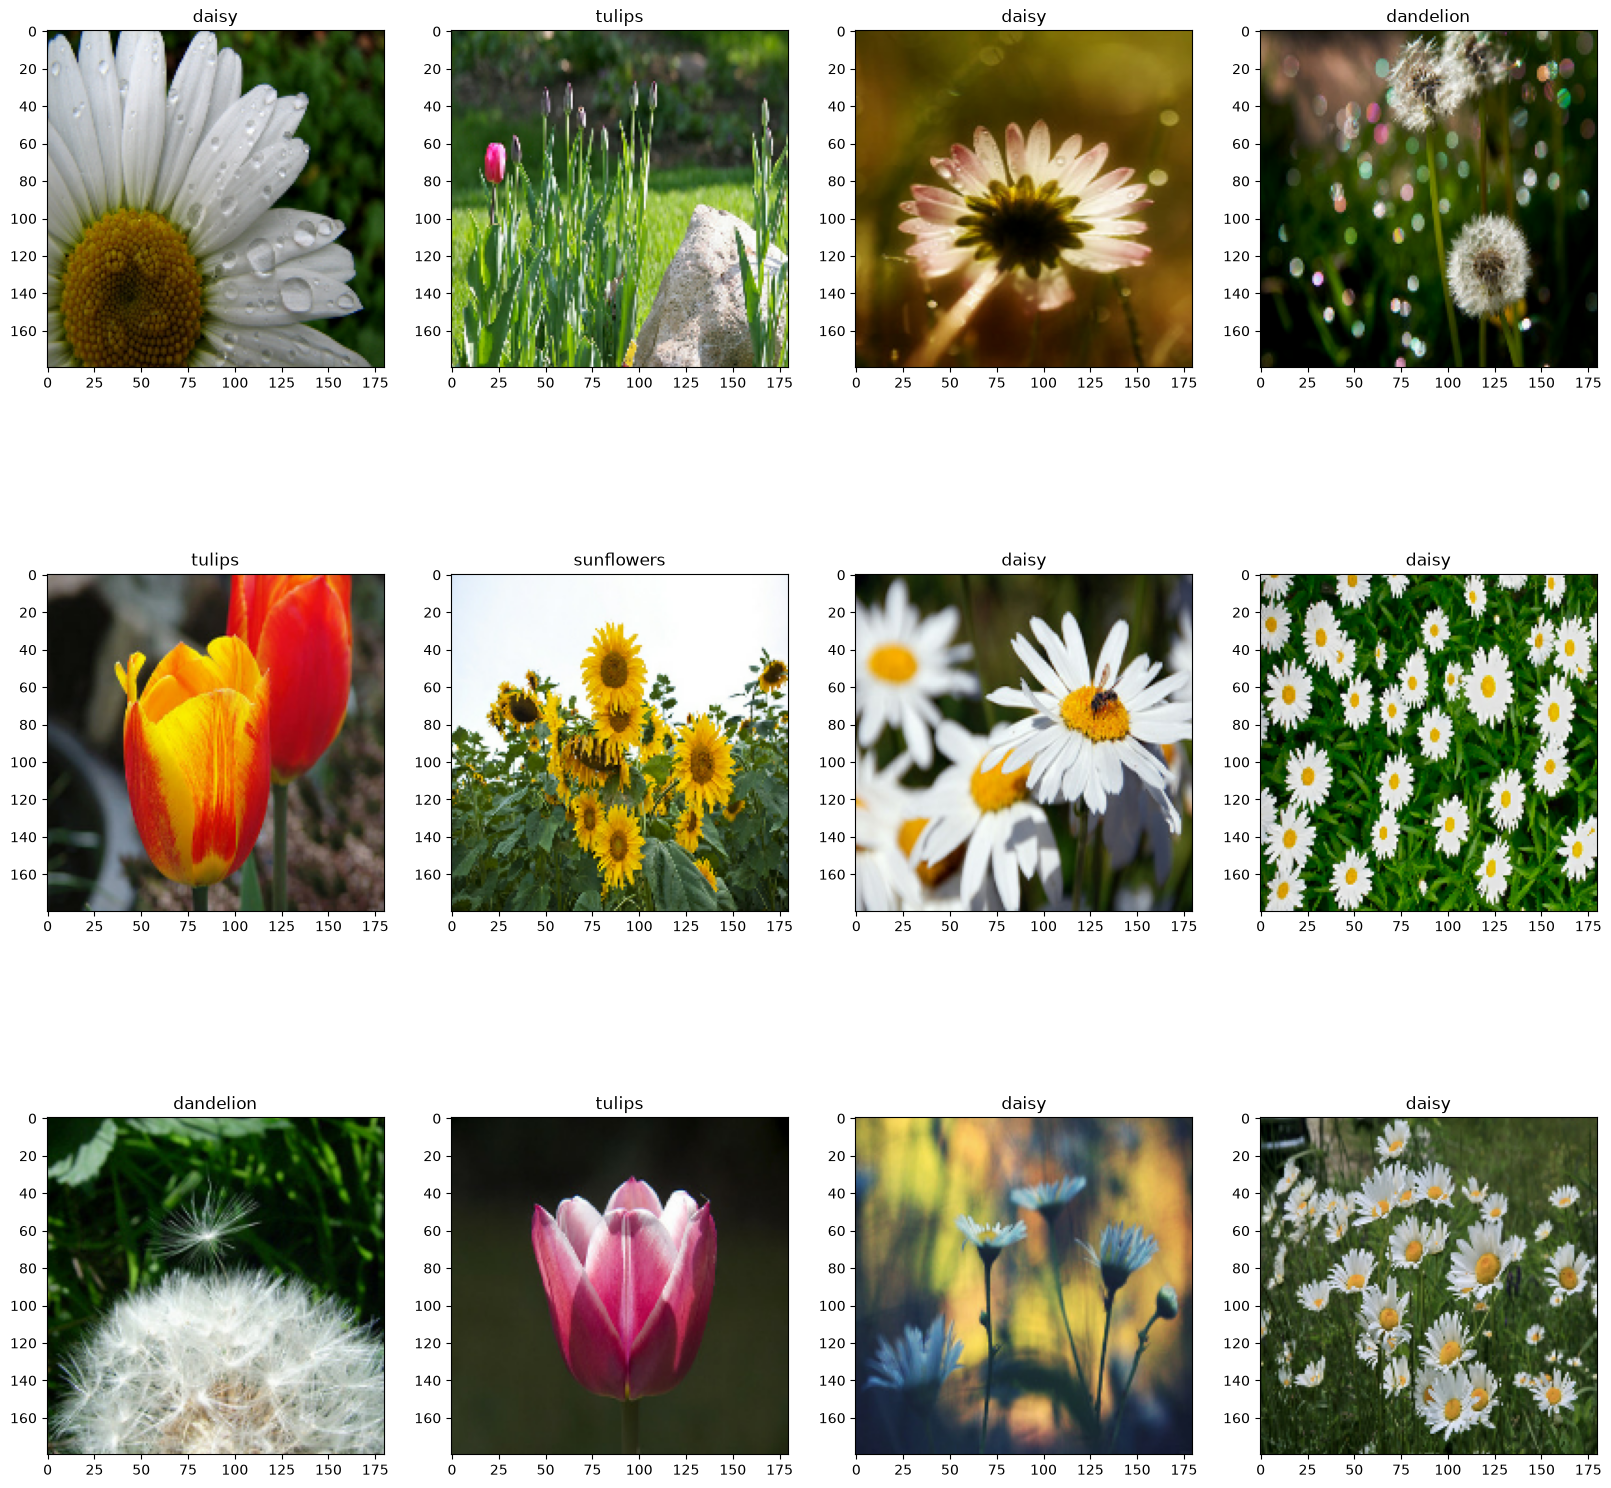

In [6]:
#import matplotlib.pyplot as plt
plt.figure (figsize=(20,20))
for images, labels in train_set.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i+1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]])
        plt.axis('on')

In [8]:
#bees (natural) and bags (not natural)
# Size of the data - manage model performance 
# type of train_set - is BatchDataset - an object containing image batches
# Take an element from train_set and display the first batch. 
# Tensor (n-dimensional matrix) of the form (32,180,180,3)
# 32 images of dimensions 180 x 180 x 3(RGB Channel)
# label_batch variable is a tensor f the form 32

print (type(train_set))
images, labels = next(iter(train_set))
print(images.shape)
print(labels.shape)

<class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>
(32, 180, 180, 3)
(32,)


In [9]:
# Setup the training environment - configure the data - improve performance
# Dataset.cache() - force data to be cached in memory
    #As neural network makes several passes called Epoch over the data during training
    #function avoids having to reload the images each time.
# Dataset.prefetch() - preprocesses the current element of the dataset, e.g) the next batch 
    # ...as the model trains/ evaluates the current batch.
    # In a multi-core environment, or multi-processor it saves considerable time. 
# Use early Epoch stop to stop iteration to save resources 
AUTOTUNE = tf.data.experimental.AUTOTUNE
train_set = train_set.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
test_set = test_set.cache().prefetch(buffer_size=AUTOTUNE)

In [10]:
# Normalization 
# Transform the value scale of attributes - to take values in the same interval
# Makes learning more uniform across different attributes
# & therefore, not overestimating the importance of one attribute compared to another 
# ...when having completely different scales
# Dividing the input (the value of a pixel's RGB component) by 255 
# ... to transform the input into the interval [0,1]. 
# use the function layers.experimental.preprocessing.Rescaling
rescaleLayer = tf.keras.layers.Rescaling(scale=1./127.5, offset=-1.0)

In [11]:
# CNN - Convolutional Neural Network model (CV - Computer Vision)
# it's a specialized neural network architecture designed to effectively learn CV tasks
# Distinctive feature - inclusion of convolutional layer in the hidden layers.
# Edge detection - detection of contours in addition to 
#........................................corner & blob
# ... (significantly reduces amount of data kept - only keeps info deemed relevant)
# most methods can be grouped in to two categories: 
# ... (1) Extremums of the first derivate and 
# ... (2) cancellation of the second derivative, 
# ... or cancellation of the laplacian or of a non-linear differential expression
# Corner 
# Blob
# deeper layers rely on earlier layers
# earlier layers - detect higher level attributes of the input data
# low-level features mentioned in (edges, corners, blobs)
# high-level features - presence of certain patterns, textures, or shapes constructed from 
#... low level attributes.
# Image's attributes: Hierarchy, Locality, and Spatial Invariance
# .............1) Hierarchy: each layer will be used to extract features useful 
# ..............for the task by building on the features/ attributes extracted 
#...............by the previous layer. A neural nwk is simply a compact (compressed)
#...............representation of the image. It explains the use of neural nwks 
#...............in image classification and computer vision tasks in general. 

#..... 2) Locality

num_classes = 5 
#...no. of classes and ... also number of neurons in the last layer
model_with_dropout = Sequential()



In [18]:
# In ML - transform the value scale of features - falls within the same range
#... Transformation helps models learn consistently across different features
#... preventing of an overemphasis of one feature over another - completely different scales of features
# Normalization - dividing input by 255 
#... input - the value of a pixel's RGB component 
#... /255 - to transform the input into the interval [0, 1]
# Legacy module: layers.experimental.preprocessing.Rescaling
# Currently use: layers.Rescaling

#model.add(tf.keras.layers.Rescaling(
#    1./255, input_shape = (image_h, image_w, 3)
#))

#model = Sequential([
#    Input(shape=(image_h, image_w, 3)),
#    Rescaling(1./255),
#    Dense(128, activation='relu'),
#    Dense(10)
#])

In [19]:
#Convolution Layer 
#model.add(
#    layers.Conv2D(16, 3, padding='same', activation='relu')
#)

#pooling layer 
#model.add(
#    layers.MaxPooling2D()
#)

In [20]:
# Convolution block or filter size is (32,3)
#model.add(layers.Conv2D(32,3, padding = 'same', activation = 'relu'))
#model.add(layers.MaxPooling2D())

#Convolution block or filter size is (64, 3)
#model.add(layers.Conv2D(64, 3, padding = 'same', activation = 'relu'))
#model.add(layers.MaxPooling2D())

#
#Layer flattening 
#model.add(layers.Flatten())

#Fully connected layer (dense layer)
#model.add(layers.Dense(128, activation = 'relu'))

#Fully connected layer returns classification result 
#model.add(layers.Dense(num_classes))

In [21]:
#Optimization algorithm used (for sgd or adam), as well as ...
#...The Cost (Loss) function
#... & the metric to evaluate the network's performance 
#model.compile(optimizer = \
#             'adam', 
#             loss = \
#             tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
#             metrics=['accuracy'])

#model.summary()

In [2]:
# Specify the evolution of the training error and compare it with the test error
# training requires the training set, the test set, and no. of epochs

data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal', input_shape=(image_h, image_w, 3)),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

model_with_dropout = Sequential ([
    data_augmentation,
    layers.Rescaling(1./255, input_shape = (image_h, image_w, 3)),
    layers.Conv2D(16, 3, padding='same', activation = 'relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation = 'relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding = 'same', activation = 'relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.35),
    layers.Flatten(),
    layers.Dense(128, activation = 'relu'),
    layers.Dense(num_classes)
    
])

#Compile the Model
model_with_dropout.compile(optimizer = 'adam',
                          loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits = True),
                          metrics = ['accuracy'])
#Model Summary
model_with_dropout.summary()

#Model training
# Transfer Learning - 5 to 15 Epochs 
# Custom CNNs - 20 to 50 Epochs
# Complex Models - 50 to 100 plus Epochs

# Simple Visual Classification (Cats vs. Dogs MNIST)
epochs = 100

callbacks = [
    keras.callbacks.EarlyStopping(
    monitor = 'val_loss', patience = 8, min_delta=1e-3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor = 0.5,
        patience=3, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint(
        'model_autostopset.keras', monitor='val_loss', save_best_only=True),]

history = model_with_dropout.fit(train_set, 
                                 validation_data = test_set, 
                                 epochs = epochs, 
                                 callbacks = callbacks,)




acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochCounter = len (history.history['loss'])
epochs_range = range(1, epochCounter + 1 )
epochOptimizer = int(np.argmin(history.history['val_loss'])) + 1
print (f'Training stopped after {epochCounter} epochs; Optimum epoch = {epochOptimizer}')

plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label = 'Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Trianing and Validation Accuracy')

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label = 'Training Loss')
plt.plot(epochs_range, val_loss, label = 'Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

NameError: name 'keras' is not defined

In [1]:
def test_model(model_with_dropout, dataset, class_names):
    test_acc, test_loss = model_with_dropout.evaluate(dataset, verbose=0)
    print(f"\n Test Accuracy: {test_acc:.2f} | Test Loss: {test_loss:.2f}")

    return test_acc, test_loss

test_model(model_with_dropout, test_set_real, class_names)
plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Test Accuracy')
plt.plot(epochs_range, val_acc, label = 'Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Test and Validation Accuracy')

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label = 'Test Loss')
plt.plot(epochs_range, val_loss, label = 'Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

NameError: name 'model_with_dropout' is not defined

In [2]:
test_model(model, test_set, class_names)

NameError: name 'model' is not defined